# Dados retrospectivos de focos detectáveis

Notebook regenerado na auditoria de 23/10/2026. Não estima incêndios independentes, área queimada ou disponibilidade operacional. Resultados antigos continuam no histórico Git. POWER legada LST e focos UTC exigem revisão de alinhamento.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))


In [2]:
grid = pd.read_csv(ROOT / 'data/processed/grid.csv')
df = pd.read_parquet(ROOT / 'data/processed/dataset.parquet')
df = df[df.grid_id.isin(grid.loc[grid.state_status != 'outside', 'grid_id'])].copy()
print('Dimensions:', df.shape, 'Cells:', df.grid_id.nunique())
print('Observed date range:', df.date.min(), df.date.max())
display(df.head())
display(df[['target_1d','target_3d','target_7d']].mean().rename('positive_cell_day_rate'))


Dimensions: (1283392, 16) Cells: 352
Observed date range: 2016-01-01 00:00:00 2025-12-24 00:00:00


,grid_id,date,fire_count,target_1d,target_3d,target_7d,target,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M,grid_row,grid_col,lat_center,lon_center
25522,000_007,2016-01-01,0,0,0,0,0,34.38,25.97,60.93,2.02,2.11,0,7,-17.85,-57.95
25523,000_007,2016-01-02,0,0,0,0,0,31.57,25.52,71.79,14.65,2.03,0,7,-17.85,-57.95
25524,000_007,2016-01-03,0,0,0,0,0,34.04,24.56,68.48,4.63,1.90,0,7,-17.85,-57.95
25525,000_007,2016-01-04,0,0,0,0,0,34.61,25.20,66.22,4.69,1.85,0,7,-17.85,-57.95
25526,000_007,2016-01-05,0,0,0,0,0,32.75,25.44,72.28,7.14,1.70,0,7,-17.85,-57.95


target_1d    0.068224
target_3d    0.158386
target_7d    0.272211
Name: positive_cell_day_rate, dtype: float64

## Cobertura e ausência

A cauda dos rótulos é truncada por exigir horizonte futuro completo. As contagens abaixo não descrevem dias descartados. Ausência de detecção não comprova ausência física de fogo.

In [3]:
display(df.isna().sum().rename('missing')); display(grid.groupby('state_status').size().rename('cells'))

grid_id        0
date           0
fire_count     0
target_1d      0
target_3d      0
target_7d      0
target         0
T2M_MAX        0
T2M_MIN        0
RH2M           0
PRECTOTCORR    0
WS10M          0
grid_row       0
grid_col       0
lat_center     0
lon_center     0
Name: missing, dtype: int64

state_status
inside     266
outside    154
partial     86
Name: cells, dtype: int64

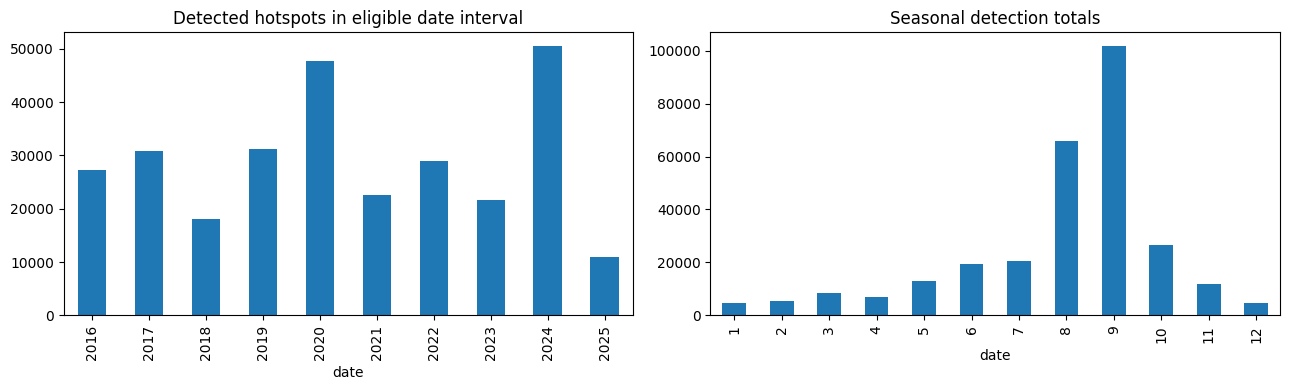

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(df.date.dt.year).fire_count.sum().plot.bar(ax=axes[0], title='Detected hotspots in eligible date interval')
df.groupby(df.date.dt.month).fire_count.sum().plot.bar(ax=axes[1], title='Seasonal detection totals')
plt.tight_layout(); plt.show()


In [5]:
weather = ['T2M_MAX','T2M_MIN','RH2M','PRECTOTCORR','WS10M']
display(df.groupby('target')[weather].mean())
display(grid[['cell_area_km2','state_area_km2','state_fraction_geodesic']].describe())


,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M
target,,,,,
0,32.091029,21.925817,69.366766,3.800866,1.685455
1,33.521231,21.929259,61.531097,2.433518,1.593705


,cell_area_km2,state_area_km2,state_fraction_geodesic
count,506.000000,506.000000,506.000000
mean,3000.574893,1785.009273,0.595293
std,36.474016,1385.461187,0.462016
min,2932.827899,0.000000,0.000000
25%,2970.283778,0.000000,0.000000
50%,3005.050891,2948.472276,0.999886
75%,3033.102563,3002.194652,1.000000
max,3052.660633,3041.604055,1.000000


Comparações climáticas por alvo são associações. Resolução da fonte, dependência espacial, cobertura do satélite e prevalência impedem interpretação causal automática. Consulte reports/REPRODUCIBILIDADE.md e reports/CLIMA_E_ABLACAO.md.